In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

sales = pd.DataFrame({
    "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    "Laptops":    [40, 42, 45, 38, 36, 35, 41, 48, 52, 85, 95, 60],
    "Phones":     [55, 54, 58, 60, 57, 59, 62, 64, 66, 90, 98, 72],
    "Headphones": [20, 22, 21, 25, 24, 26, 25, 27, 30, 45, 52, 40],
})

sales


,Month,Laptops,Phones,Headphones
0,Jan,40,55,20
1,Feb,42,54,22
2,Mar,45,58,21
3,Apr,38,60,25
4,May,36,57,24
5,Jun,35,59,26
6,Jul,41,62,25
7,Aug,48,64,27
8,Sep,52,66,30
9,Oct,85,90,45


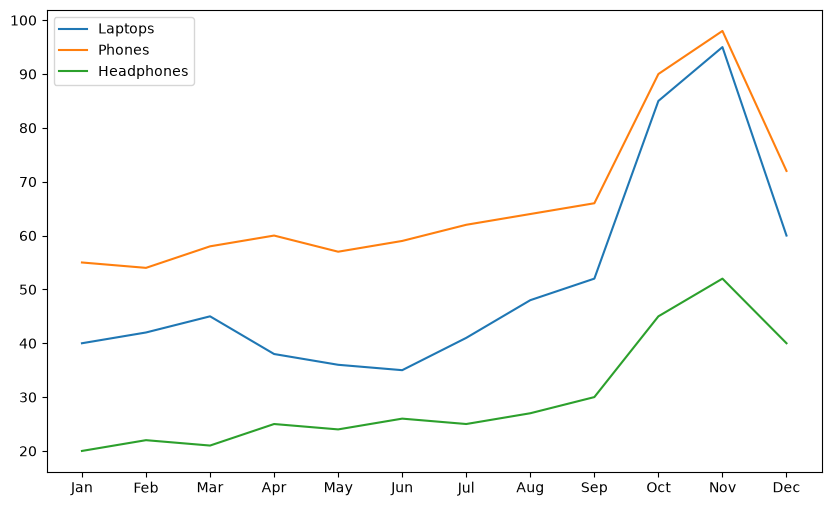

In [2]:
#Part A: The Starting Point
#Task 1: Default chart

plt.figure(figsize=(10, 6))
plt.plot(sales["Month"], sales["Laptops"], label="Laptops")
plt.plot(sales["Month"], sales["Phones"], label="Phones")
plt.plot(sales["Month"], sales["Headphones"], label="Headphones")

plt.legend()
plt.savefig("before.png")
plt.show()

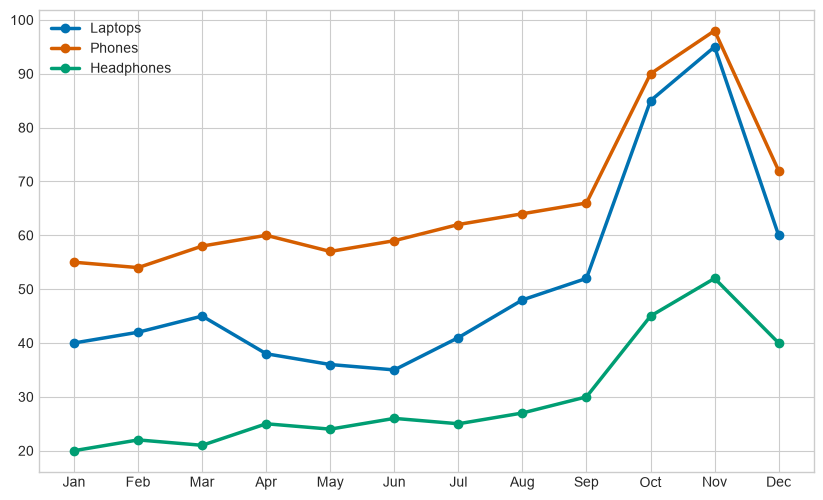

In [3]:
#Part B: Colours and Style
#Task 2: Consistent, readable colours

# Apply clean style
plt.style.use("seaborn-v0_8-whitegrid")

# Define fixed colors map
colors = {"Laptops": "#0072B2", "Phones": "#D55E00", "Headphones": "#009E73"}

plt.figure(figsize=(10, 6))
for product in ["Laptops", "Phones", "Headphones"]:
    plt.plot(
        sales["Month"], 
        sales[product], 
        label=product, 
        color=colors[product], 
        linewidth=2.5, 
        marker="o"
    )

plt.legend()
plt.show()

A product should keep the same colour in every chart to maintain visual consistency, allowing readers to instantly recognize and track that category across multiple dashboards without re-checking the legend.

Red and green should not be used together as primary categorical differentiators because they are indistinguishable for individuals with red-green color blindness (deuteranopia or protanopia).

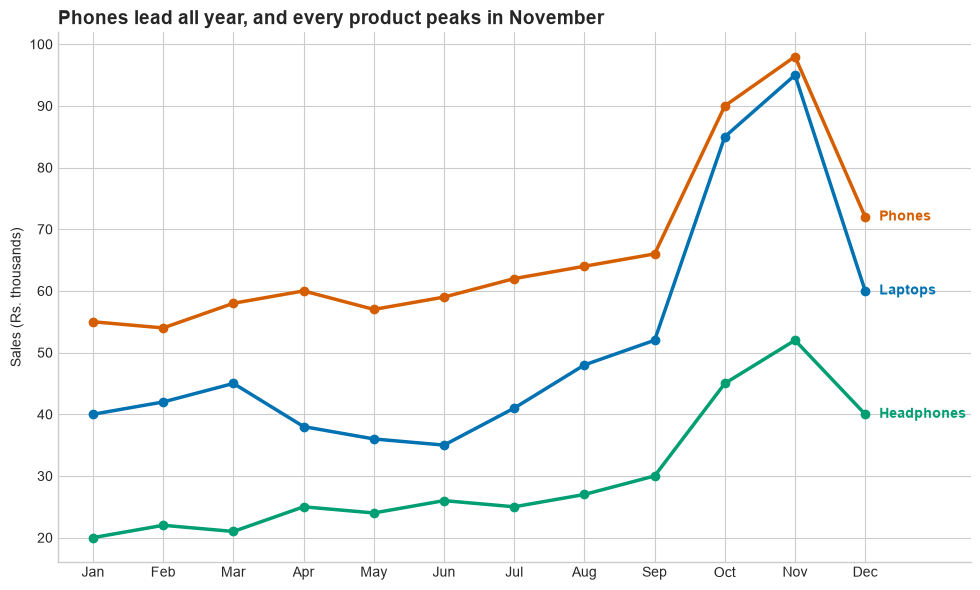

In [4]:
#Part C: Titles and Labels
#Task 3: Say what the chart shows

fig, ax = plt.subplots(figsize=(10, 6))

for product in ["Laptops", "Phones", "Headphones"]:
    ax.plot(
        sales["Month"], 
        sales[product], 
        color=colors[product], 
        linewidth=2.5, 
        marker="o"
    )
    # Direct labeling at line ends
    last_value = sales[product].iloc[-1]
    ax.text(11.2, last_value, product, color=colors[product], fontweight="bold", va="center")

# Insight-driven title & y-axis label
ax.set_title("Phones lead all year, and every product peaks in November", fontsize=14, fontweight="bold", loc="left")
ax.set_ylabel("Sales (Rs. thousands)")

# Remove top and right spines
ax.spines[["top", "right"]].set_visible(False)

plt.xlim(-0.5, 12.5) # Extend x-axis to fit line-end text
plt.tight_layout()
plt.show()

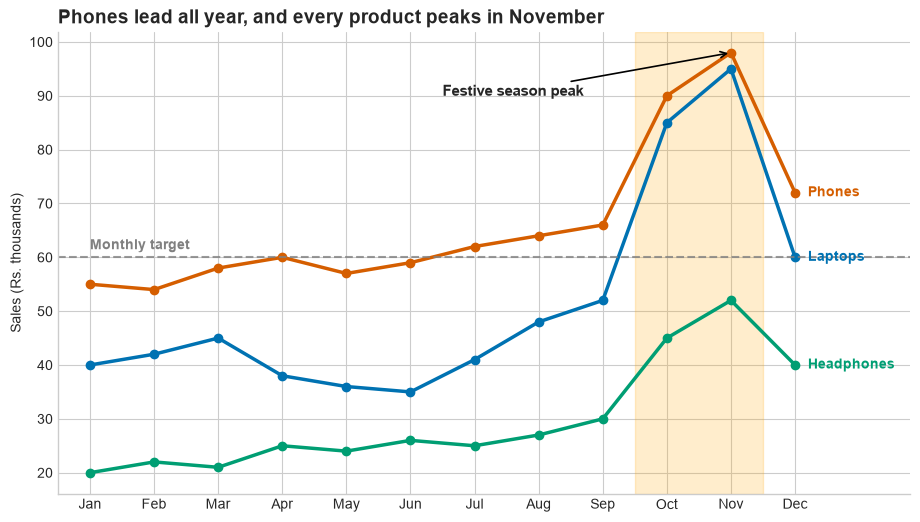

In [5]:
#Part D: Annotations and Highlights
#Task 4: Guide the reader's eye

fig, ax = plt.subplots(figsize=(11, 6))

for product in ["Laptops", "Phones", "Headphones"]:
    ax.plot(
        sales["Month"], 
        sales[product], 
        color=colors[product], 
        linewidth=2.5, 
        marker="o"
    )
    last_value = sales[product].iloc[-1]
    ax.text(11.2, last_value, product, color=colors[product], fontweight="bold", va="center")

# Title and labels
ax.set_title("Phones lead all year, and every product peaks in November", fontsize=14, fontweight="bold", loc="left")
ax.set_ylabel("Sales (Rs. thousands)")

# Remove top and right borders
ax.spines[["top", "right"]].set_visible(False)

# Annotation arrow pointing to peak
ax.annotate(
    "Festive season peak", 
    xy=(10, 98), 
    xytext=(5.5, 90), 
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=11,
    fontweight="bold"
)

# Shade festive season (October = index 9, November = index 10)
ax.axvspan(8.5, 10.5, color="orange", alpha=0.2)

# Dashed grey line at 60 (Monthly target)
ax.axhline(60, linestyle="--", color="grey", alpha=0.8)
ax.text(0, 61.5, "Monthly target", color="grey", fontweight="bold", fontsize=10)

plt.xlim(-0.5, 12.8)
plt.savefig("after.png", dpi=150, bbox_inches="tight")
plt.show()

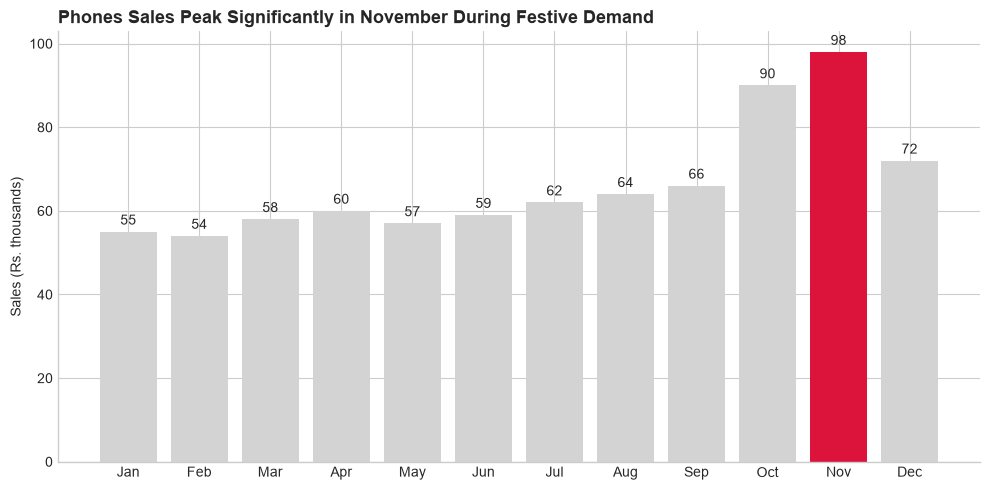

In [6]:
#Task 5: Highlight one bar

fig, ax = plt.subplots(figsize=(10, 5))

# Identify peak month
max_idx = sales["Phones"].idxmax()

# Set bar colors (light grey by default, crimson for max)
bar_colors = ["#D3D3D3"] * len(sales)
bar_colors[max_idx] = "#DC143C"  # Crimson

bars = ax.bar(sales["Month"], sales["Phones"], color=bar_colors)

# Show values above bars
ax.bar_label(bars, padding=3)

# Title & styling
ax.set_title("Phones Sales Peak Significantly in November During Festive Demand", fontsize=13, fontweight="bold", loc="left")
ax.set_ylabel("Sales (Rs. thousands)")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Colouring all background bars in a neutral light grey while making the peak bar crimson creates a strong visual pop through colour contrast, instantly drawing the human eye to the maximum value first.

In [10]:
#Part E: Customizing a Plotly Chart
#Task 6: Interactive version

# Convert to long format
long = sales.melt(id_vars="Month", var_name="Product", value_name="Sales")

fig = px.line(
    long, 
    x="Month", 
    y="Sales", 
    color="Product", 
    markers=True,
    color_discrete_map=colors, 
    template="simple_white",
    title="Phones lead all year, and every product peaks in November"
)

# Thicker lines & custom hover text
fig.update_traces(line_width=3, hovertemplate="%{x}: Rs. %{y}k")

# Update Y-axis title
fig.update_layout(yaxis_title="Sales (Rs. thousands)")

# Add Peak Annotation
fig.add_annotation(
    x="Nov", 
    y=98, 
    text="Festive season peak", 
    showarrow=True, 
    arrowhead=2
)

# Shade October to November region
fig.add_vrect(
    x0="Oct", 
    x1="Nov", 
    fillcolor="orange", 
    opacity=0.2, 
    line_width=0
)


fig.show()

In [8]:
#Part F: From Chart to Story
#Task 7: Before and after comparison

# Code to display side-by-side images in Jupyter Notebook
from IPython.display import Image, display, HTML

display(HTML("""
<div style="display: flex; justify-content: space-between;">
    <div style="width: 49%; text-align: center;">
        <h4>Before</h4>
        <img src="before.png" style="width: 100%;">
    </div>
    <div style="width: 49%; text-align: center;">
        <h4>After</h4>
        <img src="after.png" style="width: 100%;">
    </div>
</div>
"""))

Applied a clean whitegrid style and fixed brand-aligned colours: Improves visual aesthetics and ensures instant product tracking across the chart.

Replaced the generic title with an insight-driven title: Tells the decision-maker the key takeaway immediately without forcing them to decode the chart.   

Replaced the traditional legend with direct line-end labeling: Eliminates back-and-forth eye movement between the legend and the lines.   

Added a shaded festive season region and peak annotation: Highlights critical operational windows (October–November) and the exact maximum sales point.   

Introduced a reference target line at 60 (Rs. thousands): Instantly distinguishes months performing above or below the baseline target.   

#Task 8: Write the data story

Headline: Phones lead total sales throughout the year, driven by a massive market-wide surge during the October and November festive season.   

Evidence: Phone sales reached a peak of Rs. 98k in November, significantly outperforming the monthly baseline target of Rs. 60k. Similarly, Laptop sales surged to Rs. 95k in November from an average of around 40k earlier in the year.   

Recommendation: The store should ramp up inventory procurement and scale up digital marketing campaigns by September to fully capitalize on the predictable pre-festive demand spike.   